# Sampling workflow


In [2]:
from pathlib import Path

import duckdb
import pandas as pd
import pyarrow as pa
import pyarrow.parquet as pq

from sampling_mining_workflows_dsl.WorkflowBuilder import WorkflowBuilder
from sampling_mining_workflows_dsl.constraint.BoolConstraint import BoolConstraint
from sampling_mining_workflows_dsl.element.Loader import Loader
from sampling_mining_workflows_dsl.element.Repository import Repository
from sampling_mining_workflows_dsl.element.Set import Set
from sampling_mining_workflows_dsl.metadata.Metadata import Metadata
from sampling_mining_workflows_dsl.metadata.MetadataDict import MetadataDict
from sampling_mining_workflows_dsl.metadata.MetadataList import MetadataList

pd.set_option("display.max_columns", None)
pd.set_option("display.width", 200)

OUTPUT_DIR = Path("..") / "output-final"
DATA_DIR = Path("..") / "output-final" 
DATA_DIR.mkdir(exist_ok=True)

beginning_2021_timestamp = 1609459200

## Fork enrichment

Derives `fork_count` / `is_fork` from `root_edges.parquet` via a self-join (previously run
by hand as `fork_queries.sql`, now inlined here so this notebook is self-contained). Two
origins that share the same `root_commit_node_id` are considered forks of one another;
among a group sharing a root, the one(s) with the *fewest* total commits are flagged as
forks of the one with the most. Origins with no other origin sharing their root get
`fork_count = 0` / `is_fork = false`. Writes `fork_enrichment.parquet`, consumed by the
`LEFT JOIN` in the "Load & enrich" step below.

In [3]:
fork_query = f"""
COPY (
  WITH fork_groups AS (
    SELECT
      a.origin_swhid                              AS swhid,
      COUNT(DISTINCT b.origin_swhid)              AS fork_count,
      (MAX(CASE WHEN b.total_commits > a.total_commits
                THEN 1 ELSE 0 END))::BOOLEAN      AS is_fork
    FROM   read_parquet('{OUTPUT_DIR / "root_edges.parquet"}') a
    JOIN   read_parquet('{OUTPUT_DIR / "root_edges.parquet"}') b
           ON  a.root_commit_node_id = b.root_commit_node_id
           AND a.origin_swhid        <> b.origin_swhid
    GROUP  BY a.origin_swhid, a.total_commits
  ),
  solo AS (
    SELECT DISTINCT origin_swhid AS swhid
    FROM   read_parquet('{OUTPUT_DIR / "root_edges.parquet"}')
    WHERE  origin_swhid NOT IN (SELECT swhid FROM fork_groups)
  )
  SELECT swhid, fork_count, is_fork FROM fork_groups
  UNION ALL
  SELECT swhid, 0 AS fork_count, false AS is_fork FROM solo
) TO '{OUTPUT_DIR / "fork_enrichment.parquet"}' (FORMAT PARQUET, COMPRESSION 'zstd')
"""

duckdb.connect().execute(fork_query)
print(f"fork_enrichment.parquet written to {OUTPUT_DIR / 'fork_enrichment.parquet'}")

fork_enrichment.parquet written to ../output-final/fork_enrichment.parquet


## Parquet loader

The DSL (v0.0.1) ships loaders for JSON and CSV only (`LoaderFactory.json_loader`,
`element.loader.CsvLoader.CsvLoader`). Our data lives in Parquet, so we add a small
`ParquetLoader` that runs a DuckDB query and turns each resulting row into a `Repository`,
the same way `CsvLoader`/`JsonLoader` do internally.

Going through DuckDB also means booleans and numbers arrive already typed (`True`/`False`,
`int`), instead of the `"True"`/`"False"` strings a CSV round-trip would produce — which
matters because `MetadataBoolean` coerces untyped values with plain `bool(...)`, and
`bool("False")` is `True` in Python.


In [4]:
class ParquetLoader(Loader):
    """Loads a DSL Set from the result of an arbitrary DuckDB SQL query."""

    def __init__(self, query: str, *metadatas: Metadata):
        super().__init__(*metadatas)
        self.query = query

    def load_set(self) -> Set:
        result_set = Set()
        con = duckdb.connect()
        cursor = con.execute(self.query)
        columns = [c[0] for c in cursor.description]
        for row in cursor.fetchall():
            row_map = dict(zip(columns, row))
            result_set.add_element(self._create_repository_from_map(row_map))
        return result_set

    def _create_repository_from_map(self, row_map: dict) -> "Repository":
        id_value = row_map.get(self.metadata_id_name)
        if id_value is None or id_value == "":
            raise ValueError(f"Invalid ID {self.metadata_id_name}")

        repo = Repository(self.metadatas[self.metadata_id_name])
        metadata_values = [
            metadata.create_metadata_value(row_map.get(metadata.name))
            for metadata in self.metadatas.values()
        ]
        repo.add_metadata_values(metadata_values)
        return repo


## Parquet writer

Symmetrically, the DSL only ships a `CsvWriter`/`JsonWriter`. `ParquetWriter` writes a
(flat) `Set` of `Repository` elements out via PyArrow. `lang_counts` and
`yearly_head_revisions` are DSL `MetadataDict` values (Python `dict`s) — PyArrow's usual
dict-column inference turns those into a wide `struct` (one field per distinct key across
*all* rows), so those columns are built explicitly as Arrow `map` arrays to preserve the
same `MAP` type `origins.parquet` uses.


In [5]:
_ARROW_SCALAR_TYPES = {str: pa.string(), int: pa.int64(), float: pa.float64(), bool: pa.bool_()}


class ParquetWriter:
    """Writes a depth-1 Set of Repository elements to a Parquet file."""

    def __init__(self, set_path: str):
        self.set_path = Path(set_path)

    def write_set(self, set_obj: Set):
        if not isinstance(set_obj, Set):
            raise TypeError("Expected a Set object")

        repositories = list(set_obj.elements.values())
        if not repositories:
            raise ValueError("The set is empty. Nothing to write.")

        metadatas = list(repositories[0].get_all_metadata_values().keys())
        columns = {
            meta.name: self._to_arrow_array(
                meta, [repo.get_metadata_value(meta).get_value() for repo in repositories]
            )
            for meta in metadatas
        }

        pq.write_table(pa.table(columns), self.set_path)
        print(f"Parquet has been written to {self.set_path}")

    @staticmethod
    def _to_arrow_array(meta: Metadata, values: list):
        if isinstance(meta, MetadataDict):
            key_type, value_type = meta.full_type.__args__
            arrow_type = pa.map_(_ARROW_SCALAR_TYPES[key_type], _ARROW_SCALAR_TYPES[value_type])
            return pa.array([list(v.items()) for v in values], type=arrow_type)
        if isinstance(meta, MetadataList):
            arrow_type = pa.list_(_ARROW_SCALAR_TYPES[meta.full_type.__args__[0]])
            return pa.array(values, type=arrow_type)
        return pa.array(values)


## Metadata schema

One `Metadata` per column of `origins.parquet` (kept in full in the output)


In [6]:
id_ = Metadata.of_string("swhid")
url = Metadata.of_string("url")
head_swhid = Metadata.of_string("head_swhid")
head_branch = Metadata.of_string("head_branch")
total_commits = Metadata.of_integer("total_commits")
recent_commits = Metadata.of_integer("recent_commits")
creation_ts = Metadata.of_integer("creation_ts")
latest_ts = Metadata.of_integer("latest_ts")
unique_authors = Metadata.of_integer("unique_authors")
core_authors = Metadata.of_integer("core_authors")
file_count = Metadata.of_integer("file_count")
estimated_size_bytes = Metadata.of_integer("estimated_size_bytes")
has_ci = Metadata.of_boolean("has_ci")
has_license = Metadata.of_boolean("has_license")
has_readme = Metadata.of_boolean("has_readme")
top_language = Metadata.of_string("top_language")
lang_counts = Metadata.of_dict("lang_counts", str, int)
yearly_head_revisions = Metadata.of_dict("yearly_head_revisions", str, str)
yearly_head_commits_3m = Metadata.of_dict("yearly_head_commits_3m", str, int)
is_fork = Metadata.of_boolean("is_fork")

all_metadata = [
    id_,
    url,
    head_swhid,
    head_branch,
    total_commits,
    recent_commits,
    creation_ts,
    latest_ts,
    unique_authors,
    core_authors,
    file_count,
    estimated_size_bytes,
    has_ci,
    has_license,
    has_readme,
    top_language,
    lang_counts,
    yearly_head_revisions,
    yearly_head_commits_3m,
    is_fork,
]

## Load & enrich


In [7]:
enrich_query = f"""
WITH enriched AS (
  SELECT
    o.*,
    COALESCE(f.fork_count, 0)  AS fork_count,
    COALESCE(f.is_fork, false) AS is_fork
  FROM read_parquet('{OUTPUT_DIR / "origins.parquet"}') o
  LEFT JOIN read_parquet('{OUTPUT_DIR / "fork_enrichment.parquet"}') f ON o.swhid = f.swhid
)
SELECT * FROM enriched
"""

parquet_loader = ParquetLoader(enrich_query, *all_metadata)

## Yearly-uniqueness constraint (pure Python)



In [8]:
def yearly_revision(yearly_head_revisions: dict, year: str) -> str | None:
    """Revision recorded under `year`'s own map key, or None if that year has no
    genuine checkpoint of its own (see OriginExtraction::yearly_head_revisions in
    src/model/origin.rs). By construction there is at most one key per year."""
    return next((rev for date, rev in yearly_head_revisions.items() if date[:4] == year), None)


def yearly_uniqueness_flags(yearly_head_revisions: dict) -> dict[str, bool]:
    """One flag per target year: has its own revision, distinct from the adjacent
    reference year. "!=" against a missing (None) reference year is always True, so
    2021 (2020 never exists) only needs its own revision to be non-None."""
    rev_2020 = yearly_revision(yearly_head_revisions, "2020")
    rev_2021 = yearly_revision(yearly_head_revisions, "2021")
    rev_2023 = yearly_revision(yearly_head_revisions, "2023")
    rev_2024 = yearly_revision(yearly_head_revisions, "2024")
    rev_2025 = yearly_revision(yearly_head_revisions, "2025")
    rev_2026 = yearly_revision(yearly_head_revisions, "2026")

    return {
        "is_unique_2021": (rev_2021 is not None) and ((rev_2020 is None) or (rev_2021 != rev_2020)),
        "is_unique_2024": (rev_2024 is not None) and ((rev_2023 is None) or (rev_2024 != rev_2023)),
        "is_unique_2026": (rev_2026 is not None) and ((rev_2025 is None) or (rev_2026 != rev_2025)),
    }


def has_unique_yearly_checkpoints(yearly_head_revisions: dict) -> bool:
    return all(yearly_uniqueness_flags(yearly_head_revisions).values())

## Sampling workflow

In [9]:
workflow = (
    WorkflowBuilder()
    .input(parquet_loader)
    # -- Activity --
    
    .filter_operator(
        f" creation_ts < {beginning_2021_timestamp} and recent_commits >= 100 "
        "and total_commits >= 1000 and unique_authors >= 5 and core_authors >= 2"
    )
    # -- Practice --
    .filter_operator("has_ci and has_license and has_readme and not is_fork")

    # -- Codebase --
            .filter_operator(
                "file_count >= 10 and (top_language == 'Java' or top_language == 'Python')")

    .filter_operator( BoolConstraint(None, has_unique_yearly_checkpoints, yearly_head_revisions))
    .stratified_random_operator(25, "top_language == 'Java'", "top_language == 'Python'")
    .union_operator()
    .output(ParquetWriter(str(DATA_DIR / "passing_origins_sample.parquet")))
)
workflow.execute_workflow()
yearly_filter_operator = workflow.get_operator_by_position(4)

# Diagnostic: of the origins that already passed Activity/Codebase/Intent/Ecosystem,
# how many additionally fail the yearly-uniqueness filter, and why?
kept_ids = {element.get_id() for element in yearly_filter_operator.get_output().get_elements()}
failing_elements = [
    element
    for element in yearly_filter_operator.get_input().get_elements()
    if element.get_id() not in kept_ids
]
total_before_yearly = yearly_filter_operator.get_input().size()

print(
    f"Rows failing the yearly-uniqueness filter: {len(failing_elements)} / {total_before_yearly} "
    f"({len(failing_elements) / total_before_yearly:.1%}) "
    "[among origins that already passed Activity/Codebase/Intent/Ecosystem]"
)
failing_yearly = pd.DataFrame([
    {
        "swhid": element.get_id(),
        "url": element.get_metadata_value(url).get_value(),
        **yearly_uniqueness_flags(element.get_metadata_value(yearly_head_revisions).get_value()),
    }
    for element in failing_elements
])
failing_yearly

Filtering elements: 100%|██████████| 912/912 [00:00<00:00, 93909.24element/s]


Parquet has been written to ../output-final/passing_origins_sample.parquet
Rows failing the yearly-uniqueness filter: 912 / 912 (100.0%) [among origins that already passed Activity/Codebase/Intent/Ecosystem]


,swhid,url,is_unique_2021,is_unique_2024,is_unique_2026
0,swh:1:ori:3de231623727d25a8235c8057b8b80fe294d...,https://github.com/Pyomo/pyomo,True,True,True
1,swh:1:ori:eb67eb31ab783607b5984f37ac6cb12ef79c...,https://github.com/OCHA-DAP/hdx-ckan,True,True,True
2,swh:1:ori:ad5b5ad04f74dc45afd77190ae64e0b7cbce...,https://github.com/cockpit-project/bots,True,True,True
3,swh:1:ori:85b94253d7958cea4b965993626b81019b2d...,https://github.com/spring-projects/spring-batch,True,True,True
4,swh:1:ori:03ed8f0a26515809eda1673c03e1ed48266c...,https://github.com/twilio/twilio-java,True,True,True
...,...,...,...,...,...
907,swh:1:ori:a02fd97bd85c0cc85ca1f628a4773d1a570a...,https://github.com/languagetool-org/languagetool,True,True,True
908,swh:1:ori:6de022ba3ec16387c64c8f43e7935ab7c297...,https://github.com/quarkusio/quarkus,True,True,True
909,swh:1:ori:a662a7a7035e9a78e758ceed667d1e666703...,https://github.com/vavr-io/vavr,True,True,True
910,swh:1:ori:b76608c637cf9eb7df8ff73bf978656046c9...,https://github.com/microsoft/OLive,True,True,True


## Workflow diagram

`WorkflowVisualizer` walks the executed workflow (operators + set sizes at each step,
including the two stratification branches) and renders it as an SVG via Graphviz.


Workflow graph saved to ../output-final/workflow_graph
Editable Graphviz source saved to ../output-final/workflow_graph.dot
HTML page saved to ../output-final/workflow.html


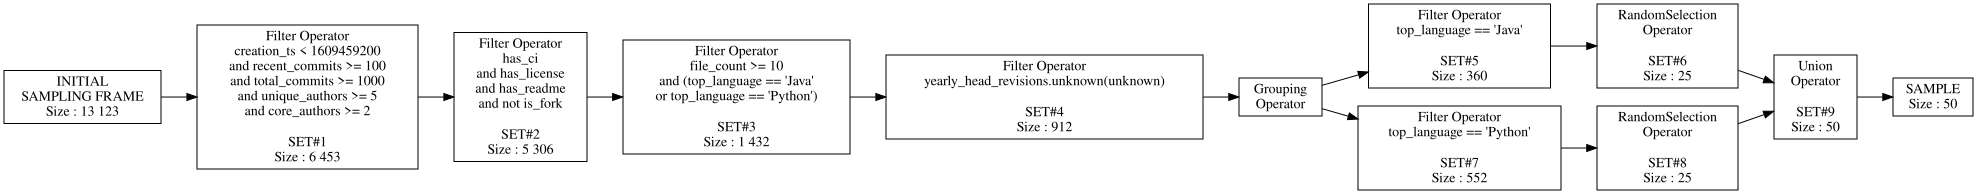

In [10]:
from IPython.display import SVG, display

from sampling_mining_workflows_dsl.exec_visualizer.WorkflowVisualizer import WorkflowVisualizer

visualizer = WorkflowVisualizer(workflow, output_dir=str(DATA_DIR), wrap_constraint_operators=True)
visualizer.generate_graph("workflow_graph")
display(SVG(str(DATA_DIR / "workflow_graph.svg")))


In [11]:
from sampling_mining_workflows_dsl.analysis.KSWorkflowAnalysis import KSWorkflowAnalysis
KSWorkflowAnalysis(metadata=total_commits,output_path="result").analyze(workflow)

KS Analysis results will be saved in result/ks_analysis.txt
Analyzing sets 0 from Set #0Initial set and 0 from Set #0Initial Input
  [PASSED] KS Statistic: 0.0, P-value: 1.0
Analyzing sets 0 from Set #0Initial set and 1 from Set #1FilterOperator
  [FAILED] KS Statistic: 0.3115141354873123, P-value: 0.0
Analyzing sets 0 from Set #0Initial set and 2 from Set #2FilterOperator
  [FAILED] KS Statistic: 0.3115141354873123, P-value: 0.0
Analyzing sets 0 from Set #0Initial set and 3 from Set #3FilterOperator
  [FAILED] KS Statistic: 0.311742741751124, P-value: 5.844999323616417e-112
Analyzing sets 0 from Set #0Initial set and 4 from Set #4FilterOperator
  [FAILED] KS Statistic: 0.3127333688943077, P-value: 1.2656697335126595e-74
Analyzing sets 0 from Set #0Initial set and 5 from Set #5FilterOperator
  [FAILED] KS Statistic: 0.3249102508742072, P-value: 2.157465233318127e-33
Analyzing sets 0 from Set #0Initial set and 6 from Set #6RandomSelectionOperator
  [FAILED] KS Statistic: 0.3356000914425

{'passing_pairs': [{'comparison': 1,
   'set_1': 'Set #0Initial set',
   'set_2': 'Set #0Initial Input',
   'statistic': np.float64(0.0),
   'p_value': np.float64(1.0),
   'interpretation': 'No significant difference (p > 0.05)'},
  {'comparison': 11,
   'set_1': 'Set #1FilterOperator',
   'set_2': 'Set #1FilterOperator',
   'statistic': np.float64(0.0),
   'p_value': np.float64(1.0),
   'interpretation': 'No significant difference (p > 0.05)'},
  {'comparison': 12,
   'set_1': 'Set #1FilterOperator',
   'set_2': 'Set #2FilterOperator',
   'statistic': np.float64(0.005963705553023391),
   'p_value': np.float64(0.9999310502147511),
   'interpretation': 'No significant difference (p > 0.05)'},
  {'comparison': 13,
   'set_1': 'Set #1FilterOperator',
   'set_2': 'Set #3FilterOperator',
   'statistic': np.float64(0.026534256726982453),
   'p_value': np.float64(0.3737238607211748),
   'interpretation': 'No significant difference (p > 0.05)'},
  {'comparison': 14,
   'set_1': 'Set #1FilterOp

In [12]:
KSWorkflowAnalysis(metadata=unique_authors,output_path="result").analyze(workflow)

KS Analysis results will be saved in result/ks_analysis.txt
Analyzing sets 0 from Set #0Initial set and 0 from Set #0Initial Input
  [PASSED] KS Statistic: 0.0, P-value: 1.0
Analyzing sets 0 from Set #0Initial set and 1 from Set #1FilterOperator
  [FAILED] KS Statistic: 0.2298035919229282, P-value: 2.593075097343285e-201
Analyzing sets 0 from Set #0Initial set and 2 from Set #2FilterOperator
  [FAILED] KS Statistic: 0.2426561709803664, P-value: 2.552936790212102e-196
Analyzing sets 0 from Set #0Initial set and 3 from Set #3FilterOperator
  [FAILED] KS Statistic: 0.23580549864049505, P-value: 1.2494253976118442e-63
Analyzing sets 0 from Set #0Initial set and 4 from Set #4FilterOperator
  [FAILED] KS Statistic: 0.24305558340719585, P-value: 7.548534380803759e-45
Analyzing sets 0 from Set #0Initial set and 5 from Set #5FilterOperator
  [FAILED] KS Statistic: 0.24890353662357012, P-value: 1.3729186617800012e-19
Analyzing sets 0 from Set #0Initial set and 6 from Set #6RandomSelectionOperato

{'passing_pairs': [{'comparison': 1,
   'set_1': 'Set #0Initial set',
   'set_2': 'Set #0Initial Input',
   'statistic': np.float64(0.0),
   'p_value': np.float64(1.0),
   'interpretation': 'No significant difference (p > 0.05)'},
  {'comparison': 11,
   'set_1': 'Set #1FilterOperator',
   'set_2': 'Set #1FilterOperator',
   'statistic': np.float64(0.0),
   'p_value': np.float64(1.0),
   'interpretation': 'No significant difference (p > 0.05)'},
  {'comparison': 12,
   'set_1': 'Set #1FilterOperator',
   'set_2': 'Set #2FilterOperator',
   'statistic': np.float64(0.014415172505721274),
   'p_value': np.float64(0.5738812390006641),
   'interpretation': 'No significant difference (p > 0.05)'},
  {'comparison': 13,
   'set_1': 'Set #1FilterOperator',
   'set_2': 'Set #3FilterOperator',
   'statistic': np.float64(0.02844374493003557),
   'p_value': np.float64(0.2927879894034508),
   'interpretation': 'No significant difference (p > 0.05)'},
  {'comparison': 14,
   'set_1': 'Set #1FilterOpe

In [13]:
KSWorkflowAnalysis(metadata=file_count,output_path="result").analyze(workflow)

KS Analysis results will be saved in result/ks_analysis.txt
Analyzing sets 0 from Set #0Initial set and 0 from Set #0Initial Input
  [PASSED] KS Statistic: 0.0, P-value: 1.0
Analyzing sets 0 from Set #0Initial set and 1 from Set #1FilterOperator
  [FAILED] KS Statistic: 0.15467816993452932, P-value: 7.526319467859461e-91
Analyzing sets 0 from Set #0Initial set and 2 from Set #2FilterOperator
  [FAILED] KS Statistic: 0.16771301161997104, P-value: 2.3446297772903236e-93
Analyzing sets 0 from Set #0Initial set and 3 from Set #3FilterOperator
  [FAILED] KS Statistic: 0.15177024048782956, P-value: 1.9862974188418494e-26
Analyzing sets 0 from Set #0Initial set and 4 from Set #4FilterOperator
  [FAILED] KS Statistic: 0.15923128135816184, P-value: 2.327255024348043e-19
Analyzing sets 0 from Set #0Initial set and 5 from Set #5FilterOperator
  [FAILED] KS Statistic: 0.33192380637896146, P-value: 7.221811424506953e-35
Analyzing sets 0 from Set #0Initial set and 6 from Set #6RandomSelectionOperato

{'passing_pairs': [{'comparison': 1,
   'set_1': 'Set #0Initial set',
   'set_2': 'Set #0Initial Input',
   'statistic': np.float64(0.0),
   'p_value': np.float64(1.0),
   'interpretation': 'No significant difference (p > 0.05)'},
  {'comparison': 9,
   'set_1': 'Set #0Initial set',
   'set_2': 'Set #8RandomSelectionOperator',
   'statistic': np.float64(0.21032385887373317),
   'p_value': np.float64(0.18957699136502004),
   'interpretation': 'No significant difference (p > 0.05)'},
  {'comparison': 11,
   'set_1': 'Set #1FilterOperator',
   'set_2': 'Set #1FilterOperator',
   'statistic': np.float64(0.0),
   'p_value': np.float64(1.0),
   'interpretation': 'No significant difference (p > 0.05)'},
  {'comparison': 12,
   'set_1': 'Set #1FilterOperator',
   'set_2': 'Set #2FilterOperator',
   'statistic': np.float64(0.016057568165626146),
   'p_value': np.float64(0.4347054354517942),
   'interpretation': 'No significant difference (p > 0.05)'},
  {'comparison': 13,
   'set_1': 'Set #1Fil

In [14]:
from sampling_mining_workflows_dsl.analysis.CochranWorkflowAnalysis import CochranWorkflowAnalysis
CochranWorkflowAnalysis(confidence_level=0.95,margin_error=0.20).analyze(workflow)

Set #6 produced by a random selection operator, checking sample size
Cochran's Test Analysis for set 6:
Required Sample Size: 22.5667796110442
Actual Sample Size: 25
The sample pass Cochran's test.
------------------------------------------
Set #8 produced by a random selection operator, checking sample size
Cochran's Test Analysis for set 8:
Required Sample Size: 23.048387451723652
Actual Sample Size: 25
The sample pass Cochran's test.
------------------------------------------


## Sample descriptive statistics

Min / Q1 / Median / Mean / Q3 / Max / SD for `estimated_size_bytes` (converted to MB),
`creation_ts` (converted to real dates, SD expressed as a duration in days since a
standard deviation of dates isn't itself a date), `total_commits`, `unique_authors`
and `core_authors`, computed on the 50-origin stratified sample written to
`passing_origins_sample.parquet`. Each row also gets a sparkline of its distribution
(Unicode for inline display, PNG for the LaTeX export). The LaTeX table is written to
`output-final/latex/sample_description.tex`, with sparkline images under
`output-final/latex/sparklines/`.

In [15]:
import matplotlib.pyplot as plt
import numpy as np

sample_df = pd.read_parquet(DATA_DIR / "passing_origins_sample.parquet")

SPARK_CHARS = "▁▂▃▄▅▆▇█"


def unicode_sparkline(values, bins=12):
    counts, _ = np.histogram(values, bins=bins)
    if counts.max() == counts.min():
        return SPARK_CHARS[0] * bins
    scaled = (counts - counts.min()) / (counts.max() - counts.min())
    return "".join(SPARK_CHARS[int(round(s * (len(SPARK_CHARS) - 1)))] for s in scaled)


LATEX_DIR = OUTPUT_DIR / "latex"
SPARK_DIR = LATEX_DIR / "sparklines"
SPARK_DIR.mkdir(parents=True, exist_ok=True)


def save_sparkline_png(values, name, bins=20):
    counts, _ = np.histogram(values, bins=bins)
    fig, ax = plt.subplots(figsize=(1.2, 0.28))
    ax.bar(range(len(counts)), counts, width=1.0, color="#333333")
    ax.axis("off")
    fig.subplots_adjust(left=0, right=1, top=1, bottom=0)
    fig.savefig(SPARK_DIR / f"{name}.png", dpi=200, transparent=True)
    plt.close(fig)


def describe(values):
    return {
        "Min": values.min(),
        "Q1": values.quantile(0.25),
        "Median": values.median(),
        "Mean": values.mean(),
        "Q3": values.quantile(0.75),
        "Max": values.max(),
        "SD": values.std(),
    }


rows = []

size_mb = sample_df["estimated_size_bytes"] / 1_000_000
stats = describe(size_mb)
save_sparkline_png(size_mb, "estimated_size_mb")
rows.append({
    "Metric": "Estimated size (MB)",
    "Sparkline": unicode_sparkline(size_mb),
    **{k: f"{v:.1f}" for k, v in stats.items()},
})

ts = sample_df["creation_ts"]
stats = describe(ts)
save_sparkline_png(ts, "creation_ts")
date_stats = {k: pd.to_datetime(v, unit="s").date().isoformat() for k, v in stats.items() if k != "SD"}
rows.append({
    "Metric": "Creation date",
    "Sparkline": unicode_sparkline(ts),
    **date_stats,
    "SD": f"{stats['SD'] / 86400:.0f} days",
})

for col, label in [
    ("total_commits", "Total commits"),
    ("unique_authors", "Unique authors"),
    ("core_authors", "Core authors"),
    ("file_count", "File count"),
]:
    values = sample_df[col]
    stats = describe(values)
    save_sparkline_png(values, col)
    rows.append({
        "Metric": label,
        "Sparkline": unicode_sparkline(values),
        **{k: (f"{v:.0f}" if k in ("Min", "Max") else f"{v:.1f}") for k, v in stats.items()},
    })

description_table = pd.DataFrame(rows).set_index("Metric")[
    ["Sparkline", "Min", "Q1", "Median", "Mean", "Q3", "Max", "SD"]
]
description_table

,Sparkline,Min,Q1,Median,Mean,Q3,Max,SD
Metric,,,,,,,,
Estimated size (MB),█▃▁▁▁▁▁▁▁▁▁▁,0.5,6.4,27.1,58.5,52.2,543.1,100.7
Creation date,▂▁▂▁▂▄▄▅▅█▆▇,2000-12-01,2012-03-16,2015-04-12,2014-07-04,2018-01-06,2019-12-06,1480 days
Total commits,█▂▁▁▁▁▁▁▁▁▁▁,1016,1916.8,3990.5,9181.2,7517.5,65931,13551.6
Unique authors,█▂▂▁▁▁▁▁▁▁▁▁,17,45.5,109.5,213.0,222.5,2394,361.5
Core authors,█▂▂▂▁▁▁▁▁▁▁▁,2,4.2,9.5,19.7,17.5,169,30.2
File count,█▂▂▁▁▁▁▁▁▁▁▁,85,482.2,968.0,2685.6,2046.2,22158,4686.5


In [16]:
SPARK_KEYS = {
    "Estimated size (MB)": "estimated_size_mb",
    "Creation date": "creation_ts",
    "Total commits": "total_commits",
    "Unique authors": "unique_authors",
    "Core authors": "core_authors",
    "File count": "file_count",
}

latex_lines = [
    r"\begin{table}[t]",
    r"\centering",
    r"\caption{Descriptive statistics of the sample (N=" + str(len(sample_df)) + r").}",
    r"\label{tab:sample-description}",
    r"\begin{tabular}{lcrrrrrrr}",
    r"\toprule",
    r"Metric & Distribution & Min & Q1 & Median & Mean & Q3 & Max & SD \\",
    r"\midrule",
]
for metric, key in SPARK_KEYS.items():
    stats_row = description_table.loc[metric]
    spark = f"\\includegraphics[width=1.4cm,height=0.28cm]{{sparklines/{key}.png}}"
    cells = " & ".join(str(stats_row[c]) for c in ["Min", "Q1", "Median", "Mean", "Q3", "Max", "SD"])
    latex_lines.append(f"{metric} & {spark} & {cells} \\\\")
latex_lines += [r"\bottomrule", r"\end{tabular}", r"\end{table}"]

latex_table = "\n".join(latex_lines)
(LATEX_DIR / "sample_description.tex").write_text(latex_table)
print(f"LaTeX table written to {LATEX_DIR / 'sample_description.tex'} (requires \\usepackage{{graphicx, booktabs}})")
print(latex_table)

LaTeX table written to ../output-final/latex/sample_description.tex (requires \usepackage{graphicx, booktabs})
\begin{table}[t]
\centering
\caption{Descriptive statistics of the sample (N=50).}
\label{tab:sample-description}
\begin{tabular}{lcrrrrrrr}
\toprule
Metric & Distribution & Min & Q1 & Median & Mean & Q3 & Max & SD \\
\midrule
Estimated size (MB) & \includegraphics[width=1.4cm,height=0.28cm]{sparklines/estimated_size_mb.png} & 0.5 & 6.4 & 27.1 & 58.5 & 52.2 & 543.1 & 100.7 \\
Creation date & \includegraphics[width=1.4cm,height=0.28cm]{sparklines/creation_ts.png} & 2000-12-01 & 2012-03-16 & 2015-04-12 & 2014-07-04 & 2018-01-06 & 2019-12-06 & 1480 days \\
Total commits & \includegraphics[width=1.4cm,height=0.28cm]{sparklines/total_commits.png} & 1016 & 1916.8 & 3990.5 & 9181.2 & 7517.5 & 65931 & 13551.6 \\
Unique authors & \includegraphics[width=1.4cm,height=0.28cm]{sparklines/unique_authors.png} & 17 & 45.5 & 109.5 & 213.0 & 222.5 & 2394 & 361.5 \\
Core authors & \includegraphi